# Yambda

Знакомимся с [Yambda](https://huggingface.co/datasets/yandex/yambda) — датасетом Яндекс Музыки: кто что слушал, лайкал и дизлайкал.

**Багдасарян Анри**

Ниже скачивается срез на 50 миллионов событий и связи треков с артистами и альбомами. Файлы сохраняются в `yambda` рядом с ноутбуком.


In [26]:
from pathlib import Path

from huggingface_hub import snapshot_download

DATA_DIR = Path("yambda")

snapshot_download(
    repo_id="yandex/yambda",
    repo_type="dataset",
    local_dir=DATA_DIR,
    allow_patterns=[
        "flat/50m/*.parquet",
        "album_item_mapping.parquet",
        "artist_item_mapping.parquet",
    ],
)

for path in sorted(DATA_DIR.rglob("*.parquet")):
    size_mb = path.stat().st_size / 1024**2
    print(f"{path.relative_to(DATA_DIR)}  {size_mb:.1f} MB")


Fetching 8 files: 100%|██████████| 8/8 [00:00<00:00, 934.25it/s]

album_item_mapping.parquet  52.0 MB
artist_item_mapping.parquet  36.5 MB
flat/50m/dislikes.parquet  0.9 MB
flat/50m/likes.parquet  6.8 MB
flat/50m/listens.parquet  352.0 MB
flat/50m/multi_event.parquet  366.7 MB
flat/50m/undislikes.parquet  0.2 MB
flat/50m/unlikes.parquet  2.1 MB


In [27]:
from pathlib import Path

import pyarrow.parquet as pq

DATA_DIR = Path("yambda")

FILES = {
    "flat/50m/listens.parquet": "Прослушивания: пользователь слушал трек.",
    "flat/50m/likes.parquet": "Лайки.",
    "flat/50m/dislikes.parquet": "Дизлайки.",
    "flat/50m/unlikes.parquet": "Пользователь снял лайк.",
    "flat/50m/undislikes.parquet": "Пользователь снял дизлайк.",
    "flat/50m/multi_event.parquet": "Те же события одной таблицей, тип записан в event_type.",
    "artist_item_mapping.parquet": "Какой артист у какого трека. Весь каталог, не только срез 50M.",
    "album_item_mapping.parquet": "В каком альбоме лежит трек. Тоже весь каталог.",
}

COLUMNS = {
    "uid": "id пользователя",
    "item_id": "id трека",
    "timestamp": "время события, шаг 5 секунд",
    "is_organic": "1 — человек нашёл трек сам, 0 — трек пришёл из рекомендации",
    "played_ratio_pct": "сколько процентов трека проиграно, только у прослушиваний",
    "track_length_seconds": "длина трека в секундах, только у прослушиваний",
    "event_type": "listen, like, dislike, unlike или undislike",
    "artist_id": "id артиста",
    "album_id": "id альбома",
}


def rows_label(n: int) -> str:
    text = f"{n:,}".replace(",", " ")
    if n % 10 == 1 and n % 100 != 11:
        word = "строка"
    elif n % 10 in (2, 3, 4) and n % 100 not in (12, 13, 14):
        word = "строки"
    else:
        word = "строк"
    return f"{text} {word}"


files = []
seen_columns = []

for relative, meaning in FILES.items():
    path = DATA_DIR / relative
    parquet = pq.ParquetFile(path)
    columns = [field.name for field in parquet.schema_arrow]
    for column in columns:
        if column not in seen_columns:
            seen_columns.append(column)
    files.append(
        {
            "name": path.name,
            "meaning": meaning,
            "size": path.stat().st_size,
            "rows": parquet.metadata.num_rows,
            "columns": columns,
            "is_event": path.parent.name == "50m" and path.name != "multi_event.parquet",
            "is_multi": path.name == "multi_event.parquet",
        }
    )

total_mb = sum(item["size"] for item in files) / 1024**2
event_rows = sum(item["rows"] for item in files if item["is_event"])
multi_rows = next(item["rows"] for item in files if item["is_multi"])

print(f"Всего {total_mb:.0f} МБ\n")
print("Колонки")
for column in seen_columns:
    print(f"  {column:<22} {COLUMNS.get(column, '')}")
print()

for item in files:
    columns = ", ".join(item["columns"])
    print(f"{item['name']}  —  {item['size'] / 1024**2:.1f} МБ, {rows_label(item['rows'])}")
    print(item["meaning"])
    print(f"Колонки: {columns}\n")

if multi_rows == event_rows:
    print(
        "multi_event — это не новые данные: в нём столько же строк, "
        f"сколько в отдельных файлах событий вместе ({rows_label(multi_rows)})."
    )


Всего 817 МБ

Колонки
  uid                    id пользователя
  timestamp              время события, шаг 5 секунд
  item_id                id трека
  is_organic             1 — человек нашёл трек сам, 0 — трек пришёл из рекомендации
  played_ratio_pct       сколько процентов трека проиграно, только у прослушиваний
  track_length_seconds   длина трека в секундах, только у прослушиваний
  event_type             listen, like, dislike, unlike или undislike
  artist_id              id артиста
  album_id               id альбома

listens.parquet  —  352.0 МБ, 46 467 212 строк
Прослушивания: пользователь слушал трек.
Колонки: uid, timestamp, item_id, is_organic, played_ratio_pct, track_length_seconds

likes.parquet  —  6.8 МБ, 881 456 строк
Лайки.
Колонки: uid, timestamp, item_id, is_organic

dislikes.parquet  —  0.9 МБ, 107 776 строк
Дизлайки.
Колонки: uid, timestamp, item_id, is_organic

unlikes.parquet  —  2.1 МБ, 312 972 строки
Пользователь снял лайк.
Колонки: uid, timestamp, item_id, i

## Предварительный осмотр

Дальше смотрим `multi_event`: там все события одной таблицей. Считаем `describe` по всем строкам — диапазон, пропуски, нули и число уникальных. Ноль в `is_organic` — это рекомендация, а не пропуск.

In [28]:
import pandas as pd

def profile(frame: pd.DataFrame) -> pd.DataFrame:
    rows = len(frame)
    described = frame.describe().T
    number_cols = frame.select_dtypes(include="number").columns

    zeros = pd.Series(pd.NA, index=frame.columns, dtype="Int64")
    zeros.loc[number_cols] = (frame[number_cols] == 0).sum()

    result = pd.DataFrame(index=frame.columns)
    result["тип"] = frame.dtypes.astype(str)
    result["заполнено"] = frame.notna().sum()
    result["пропуски"] = frame.isna().sum()
    result["пропуски, %"] = result["пропуски"] / rows * 100
    result["нули"] = zeros
    result["нули, %"] = zeros / result["заполнено"] * 100
    result["уникальные"] = frame.nunique(dropna=True)
    for column in ("mean", "std", "min", "25%", "50%", "75%", "max"):
        result[column] = described[column]
    return result


events = pd.read_parquet(DATA_DIR / "flat/50m/multi_event.parquet")
summary = profile(events)
display(summary)

for column in summary.index[summary["уникальные"] <= 8]:
    counts = events[column].value_counts(dropna=False).to_frame("строк")
    counts["доля, %"] = counts["строк"] / len(events) * 100
    print(column)
    display(counts)


,тип,заполнено,пропуски,"пропуски, %",нули,"нули, %",уникальные,mean,std,min,25%,50%,75%,max
uid,uint32,47790449,0,0.000000,0,0.0,10000,4.985069e+05,2.873096e+05,100.0,249400.0,494500.0,744700.0,1000000.0
timestamp,uint32,47790449,0,0.000000,1,0.000002,5052573,1.444655e+07,7.469606e+06,0.0,8185690.0,15090975.0,21061390.0,26000000.0
item_id,uint32,47790449,0,0.000000,0,0.0,934057,4.713664e+06,2.701368e+06,22.0,2395697.0,4715228.0,7050041.0,9390623.0
is_organic,uint8,47790449,0,0.000000,22913453,47.945674,2,5.205433e-01,4.995778e-01,0.0,0.0,1.0,1.0,1.0
played_ratio_pct,float64,46467212,1323237,2.768831,3461280,7.448865,160,6.475949e+01,4.408853e+01,0.0,7.0,100.0,100.0,159.0
track_length_seconds,float64,46467212,1323237,2.768831,0,0.0,499,2.074118e+02,8.921089e+01,5.0,165.0,200.0,230.0,2495.0
event_type,category,47790449,0,0.000000,<NA>,<NA>,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


is_organic


,строк,"доля, %"
is_organic,,
1,24876996,52.054326
0,22913453,47.945674


event_type


,строк,"доля, %"
event_type,,
listen,46467212,97.231169
like,881456,1.844419
unlike,312972,0.654884
dislike,107776,0.225518
undislike,21033,0.044011


### Вывод

В `multi_event` 47.8 млн событий, 10 тысяч пользователей и 934 тысячи треков. Пропуски есть только у процента прослушивания и длины трека — это строки, которые не являются прослушиваниями.

97% событий — прослушивания. Лайки занимают около 2%, дизлайки и отмены ещё реже. Органические действия и рекомендации делятся примерно пополам. У половины прослушиваний трек доигран хотя бы до конца, у четверти проиграно не больше 7%. Обычная длина трека — около трёх минут.

## Матрица взаимодействий

Цель — матрица для обучения: строка пользователь, колонка трек, в ячейке насколько они связаны. Оси берём из `uid` и `item_id`. Что класть в ячейку, решают `event_type` и `played_ratio_pct`: почти все события — прослушивания, а короткое включение слабо похоже на интерес.

Как можно заполнить ячейку:

1. Дослушал: `listen` и `played_ratio_pct > 50`, в ячейке 1.
2. Любое включение: любой `listen`, в ячейке 1.
3. Число дослушиваний: сколько раз пара прошла порог 50%.
4. Сила прослушивания: в ячейке сам `played_ratio_pct`.
5. Лайк: `event_type == like`, в ячейке 1.

Дальше фиксируем первый вариант. Повторные прослушивания одной пары схлопываются в одну единицу.

In [29]:
listened = events[events["event_type"].eq("listen") & events["played_ratio_pct"].gt(50)]
pairs = listened.groupby(["uid", "item_id"], sort=False).size()

matrix_shape = pd.Series(
    {
        "событий listen и played_ratio_pct > 50": len(listened),
        "пользователей": listened["uid"].nunique(),
        "треков": listened["item_id"].nunique(),
        "заполненных ячеек": len(pairs),
    }
)
display(matrix_shape.to_frame("значение"))

,значение
событий listen и played_ratio_pct > 50,29370391
пользователей,9207
треков,630139
заполненных ячеек,9019829


## Какие строки и колонки оставить

В матрице Listen+ 9207 строк-пользователей и 630139 колонок-треков. Дальше три способа решить, кого оставить: степень, k-core и усечённое SVD. Для каждого способа строим свою матрицу.

## Степень

Строим бинарную матрицу Listen+. Строка — пользователь, колонка — трек, в ячейке 1, если он его дослушал. Степень строки — сколько треков дослушал пользователь, степень колонки — сколько пользователей дослушали трек. Чем степень выше, тем сильнее эта строка или колонка занимает матрицу.


In [30]:
import numpy as np
import scipy.sparse as sp

user_codes, user_ids = pd.factorize(pairs.index.get_level_values("uid"), sort=False)
track_codes, track_ids = pd.factorize(pairs.index.get_level_values("item_id"), sort=False)

interaction = sp.csr_matrix(
    (np.ones(len(pairs), dtype=np.float64), (user_codes, track_codes)),
    shape=(len(user_ids), len(track_ids)),
)

user_degree = np.asarray(interaction.sum(axis=1)).ravel()
track_degree = np.asarray(interaction.sum(axis=0)).ravel()


def degree_table(degree, name):
    total = degree.sum()
    top = max(1, len(degree) // 100)
    return {
        "кто": name,
        "медиана": np.median(degree),
        "p90": np.quantile(degree, 0.9),
        "p99": np.quantile(degree, 0.99),
        "максимум": degree.max(),
        "доля единиц у топ-1%": np.sort(degree)[-top:].sum() / total,
    }


print(f"interaction: {interaction.shape[0]} × {interaction.shape[1]}, единиц {interaction.nnz}")
display(pd.DataFrame([
    degree_table(user_degree, "пользователь"),
    degree_table(track_degree, "трек"),
]))


interaction: 9207 × 630139, единиц 9019829


,кто,медиана,p90,p99,максимум,доля единиц у топ-1%
0,пользователь,672.0,2249.8,4782.7,8175.0,0.05823
1,трек,2.0,22.0,243.0,4040.0,0.37301


## k-core

Пока в матрице есть пользователь или трек меньше чем с k единицами, его убираем и степени пересчитываем. Смотрим k = 2, 5, 10 и 20.

Дальше оставляем k = 10. Пользователи при таком пороге почти не выбывают, каталог треков сжимается в несколько раз, а большая часть единиц остаётся. Эту матрицу берём следующим шагом.


In [31]:
def k_core_mask(matrix, k):
    keep_users = np.ones(matrix.shape[0], dtype=bool)
    keep_tracks = np.ones(matrix.shape[1], dtype=bool)
    while True:
        user_degree_now = np.asarray(matrix[:, keep_tracks].sum(axis=1)).ravel()
        new_users = keep_users & (user_degree_now >= k)
        track_degree_now = np.asarray(matrix[new_users].sum(axis=0)).ravel()
        new_tracks = keep_tracks & (track_degree_now >= k)
        if np.array_equal(new_users, keep_users) and np.array_equal(new_tracks, keep_tracks):
            return new_users, new_tracks
        keep_users, keep_tracks = new_users, new_tracks


core_report = []
for k in (2, 5, 10, 20):
    keep_users, keep_tracks = k_core_mask(interaction, k)
    kept = interaction[keep_users][:, keep_tracks]
    core_report.append({
        "k": k,
        "пользователей": int(keep_users.sum()),
        "треков": int(keep_tracks.sum()),
        "единиц": int(kept.nnz),
    })

display(pd.DataFrame(core_report))

K_CORE = 10
keep_users, keep_tracks = k_core_mask(interaction, K_CORE)
core = interaction[keep_users][:, keep_tracks].tocsr()
core_user_ids = user_ids[keep_users]
core_track_ids = track_ids[keep_tracks]
print(f"core k={K_CORE}: {core.shape[0]} × {core.shape[1]}, единиц {core.nnz}")


,k,пользователей,треков,единиц
0,2,9175,333620,8723285
1,5,9095,175712,8306361
2,10,8979,111899,7887859
3,20,8801,69603,7308932


core k=10: 8979 × 111899, единиц 7887859


## Усечённое SVD

Матрицу k-core раскладываем на 32 компоненты. Плотное произведение было бы размером с саму матрицу, поэтому храним две матрицы факторов: `user_factors` для пользователей и `track_factors` для треков. Сингулярные числа показывают, какая доля единиц объясняется первыми компонентами.


,матрица,строк,колонок
0,user_factors,8979,32
1,track_factors,111899,32


первая компонента объясняет 7.8%, все 32 — 23.5%


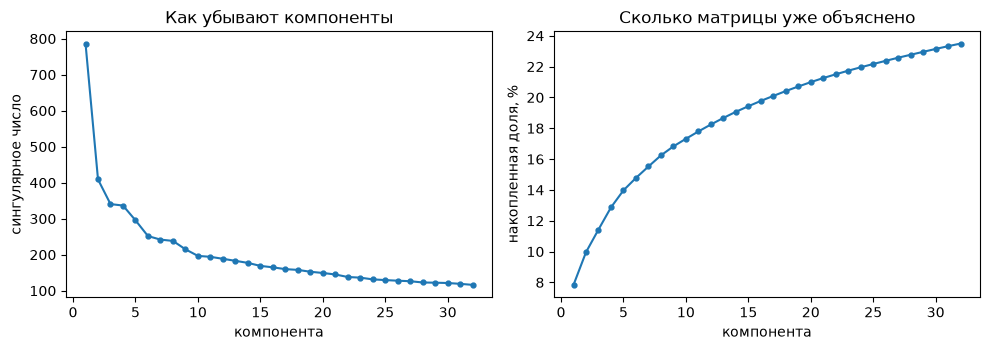

In [32]:
from scipy.sparse.linalg import svds
import matplotlib.pyplot as plt

N_COMPONENTS = 32
user_factors, singular_values, track_factors_t = svds(core, k=N_COMPONENTS, random_state=0)
order = np.argsort(singular_values)[::-1]
user_factors = user_factors[:, order]
singular_values = singular_values[order]
track_factors = track_factors_t[order].T

explained = np.cumsum(singular_values**2) / core.nnz
spectrum = pd.DataFrame({
    "компонента": np.arange(1, N_COMPONENTS + 1),
    "сингулярное число": singular_values,
    "доля матрицы, накопленная": explained,
})

factors = pd.DataFrame([
    {"матрица": "user_factors", "строк": user_factors.shape[0], "колонок": user_factors.shape[1]},
    {"матрица": "track_factors", "строк": track_factors.shape[0], "колонок": track_factors.shape[1]},
])
display(factors)
print(f"первая компонента объясняет {explained[0]:.1%}, все {N_COMPONENTS} — {explained[-1]:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
components = spectrum["компонента"]
axes[0].plot(components, spectrum["сингулярное число"], marker="o", ms=3.5)
axes[0].set_xlabel("компонента")
axes[0].set_ylabel("сингулярное число")
axes[0].set_title("Как убывают компоненты")
axes[1].plot(components, spectrum["доля матрицы, накопленная"] * 100, marker="o", ms=3.5)
axes[1].set_xlabel("компонента")
axes[1].set_ylabel("накопленная доля, %")
axes[1].set_title("Сколько матрицы уже объяснено")
fig.tight_layout()
plt.show()


### Вывод

**Степень.** Полная матрица Listen+ — 9207 × 630139, в ней 9.02 млн единиц. Пользователи активные: медиана 672 дослушанных трека, топ-1% строк собирает только 6% единиц. Треки устроены иначе: медиана 2 слушателя, а топ-1% колонок забирает 37% единиц. Матрицу занимают популярные треки.

**k-core.** При пороге 10 остаётся 8979 × 111899 и 7.89 млн единиц. Это 98% пользователей, 18% треков и 87% связей. У каждого оставшегося трека хотя бы 10 слушателей, медиана поднимается с 2 до 26. Пользователи почти не выбывают, уходит длинный хвост треков.

**SVD.** Это разложение `core` даёт две матрицы: пользователи 8979 × 32 и треки 111899 × 32. Первая компонента резко выше остальных, 786 против 409, и объясняет 8% единиц. У треков она почти совпадает с числом слушателей — это слой популярности. Дальше кривая пологая: к 32-й компоненте накоплено 23%, и спад ещё не вышел на полку. Тридцати двух факторов хватает, чтобы увидеть главные направления, и мало, чтобы восстановить саму матрицу прослушиваний.
